In [ ]:
import tensorflow as tf
import pathlib

# Download the flower dataset (this is provided free by TensorFlow/Google)
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

print("Dataset downloaded to:", data_dir)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Dataset downloaded to: /root/.keras/datasets/flower_photos


In [ ]:
import os

# List all the folders inside flower_photos - each folder = one flower type
flower_types = [item.name for item in data_dir.glob('*') if item.is_dir()]
print("Flower categories found:", flower_types)

# Count total number of images
image_count = len(list(data_dir.glob('*/*.jpg')))
print("Total number of images:", image_count)

# Count images per category
for flower in flower_types:
    count = len(list(data_dir.glob(f'{flower}/*.jpg')))
    print(f"{flower}: {count} images")

Flower categories found: ['flower_photos']
Total number of images: 0
flower_photos: 0 images


In [ ]:
# Let's see what's actually inside data_dir
for item in data_dir.glob('*'):
    print(item)

/root/.keras/datasets/flower_photos/flower_photos


In [ ]:
# Go one level deeper into the actual flower_photos folder
data_dir = data_dir / "flower_photos"
print("Corrected path:", data_dir)

# Re-check flower categories
flower_types = [item.name for item in data_dir.glob('*') if item.is_dir()]
print("Flower categories found:", flower_types)

image_count = len(list(data_dir.glob('*/*.jpg')))
print("Total number of images:", image_count)

for flower in flower_types:
    count = len(list(data_dir.glob(f'{flower}/*.jpg')))
    print(f"{flower}: {count} images")

Corrected path: /root/.keras/datasets/flower_photos/flower_photos
Flower categories found: ['roses', 'sunflowers', 'tulips', 'daisy', 'dandelion']
Total number of images: 3670
roses: 641 images
sunflowers: 699 images
tulips: 799 images
daisy: 633 images
dandelion: 898 images


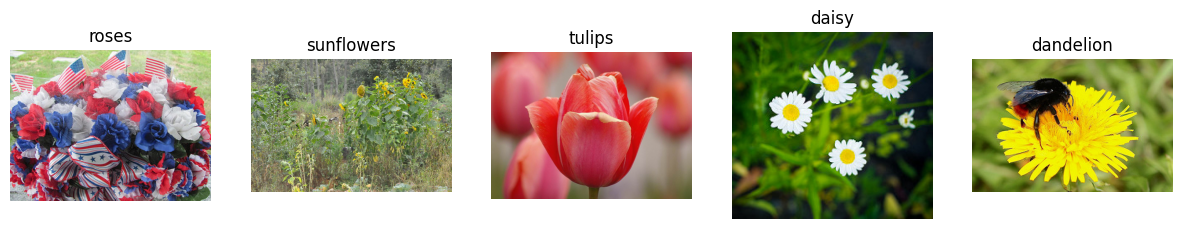

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Let's display 5 sample images, one from each flower category
plt.figure(figsize=(15, 6))

for i, flower in enumerate(flower_types):
    # Get the first image from this flower's folder
    image_path = list(data_dir.glob(f'{flower}/*.jpg'))[0]
    img = Image.open(image_path)

    plt.subplot(1, 5, i+1)
    plt.imshow(img)
    plt.title(flower)
    plt.axis('off')

plt.show()

In [ ]:
# Define standard image size and batch size
img_height = 180
img_width = 180
batch_size = 32

# Create the TRAINING dataset (80% of images)
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

# Create the VALIDATION dataset (remaining 20% of images)
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [ ]:
class_names = train_ds.class_names
print("Class names:", class_names)

Class names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [ ]:
# Normalization layer: rescales pixel values from [0,255] to [0,1]
normalization_layer = tf.keras.layers.Rescaling(1./255)

# Improve performance by caching and prefetching data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [ ]:
num_classes = len(class_names)  # This will be 5

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),

    tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes)
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,285 (15.22 MB)

 Trainable params: 3,989,285 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [ ]:
epochs = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 82ms/step - accuracy: 0.4281 - loss: 1.3465 - val_accuracy: 0.5599 - val_loss: 1.0679
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5743 - loss: 1.0326 - val_accuracy: 0.6240 - val_loss: 0.9747
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6792 - loss: 0.8301 - val_accuracy: 0.6213 - val_loss: 0.9353
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7684 - loss: 0.6327 - val_accuracy: 0.6730 - val_loss: 0.8418
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8556 - loss: 0.4116 - val_accuracy: 0.6662 - val_loss: 0.9277
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9121 - loss: 0.2608 - val_accuracy: 0.6335 - val_loss: 1.1542
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9567 - loss: 0.1405 - val_accuracy: 0.6403 - val_loss: 1.2477
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9751 - loss: 0.0930 - val_accuracy: 0.6567 - 

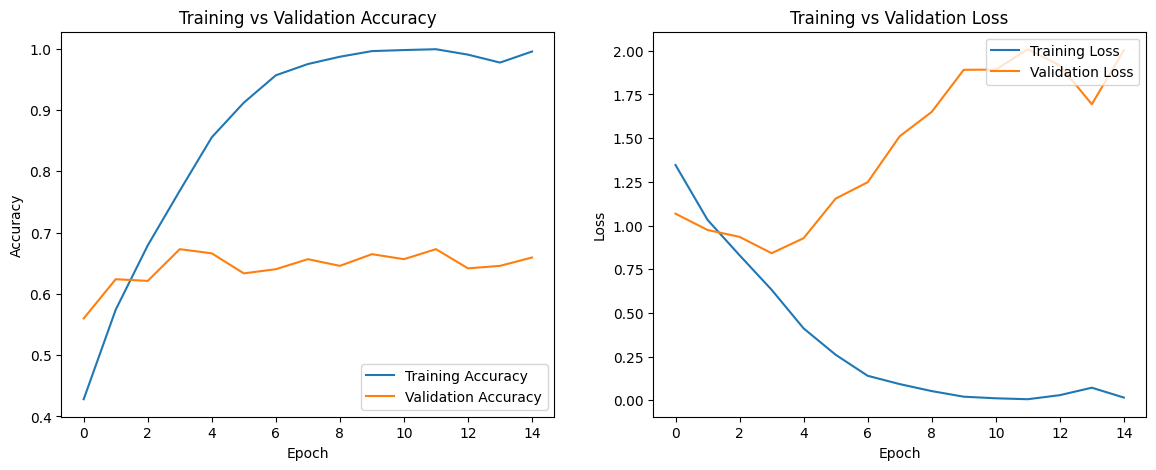

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", input_shape=(img_height, img_width, 3)),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

model = tf.keras.Sequential([
    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes)
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,285 (15.22 MB)

 Trainable params: 3,989,285 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
epochs = 15

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.4755 - loss: 1.2168 - val_accuracy: 0.5654 - val_loss: 1.1170
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.6073 - loss: 1.0011 - val_accuracy: 0.5736 - val_loss: 1.0449
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.6403 - loss: 0.9351 - val_accuracy: 0.6308 - val_loss: 0.9550
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.6723 - loss: 0.8697 - val_accuracy: 0.6512 - val_loss: 0.8954
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.6999 - loss: 0.7892 - val_accuracy: 0.6730 - val_loss: 0.8744
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.7084 - loss: 0.7636 - val_accuracy: 0.6935 - val_loss: 0.7884
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.7350 - loss: 0.6965 - val_accuracy: 0.6989 - val_loss: 0.7673
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.7483 - loss: 0.6673 - val_accuracy: 0.6948 - v

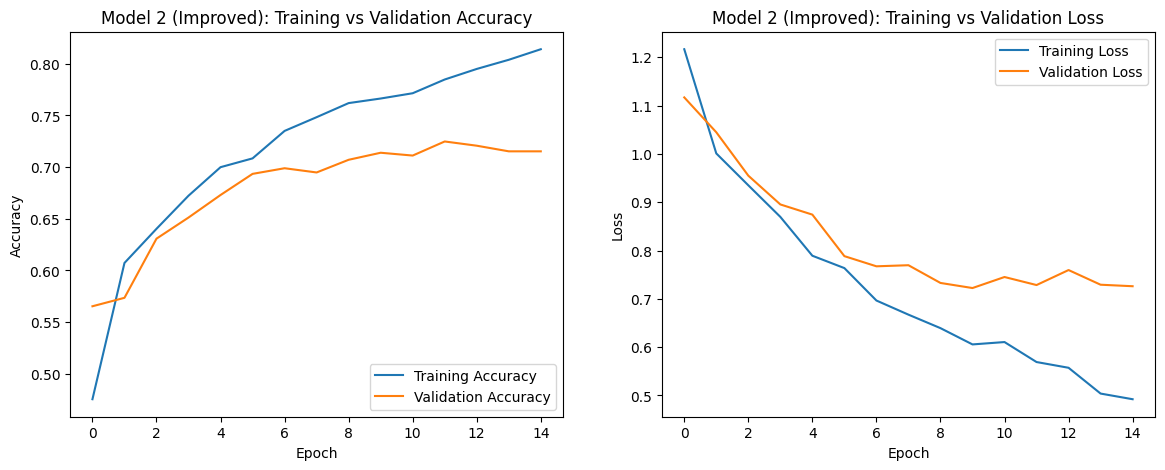

In [ ]:
acc2 = history2.history['accuracy']
val_acc2 = history2.history['val_accuracy']
loss2 = history2.history['loss']
val_loss2 = history2.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc2, label='Training Accuracy')
plt.plot(epochs_range, val_acc2, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Model 2 (Improved): Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss2, label='Training Loss')
plt.plot(epochs_range, val_loss2, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Model 2 (Improved): Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

In [ ]:
loss, accuracy = model.evaluate(val_ds)
print(f"Final Validation Accuracy: {accuracy*100:.2f}%")
print(f"Final Validation Loss: {loss:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7153 - loss: 0.7261
Final Validation Accuracy: 71.53%
Final Validation Loss: 0.7261


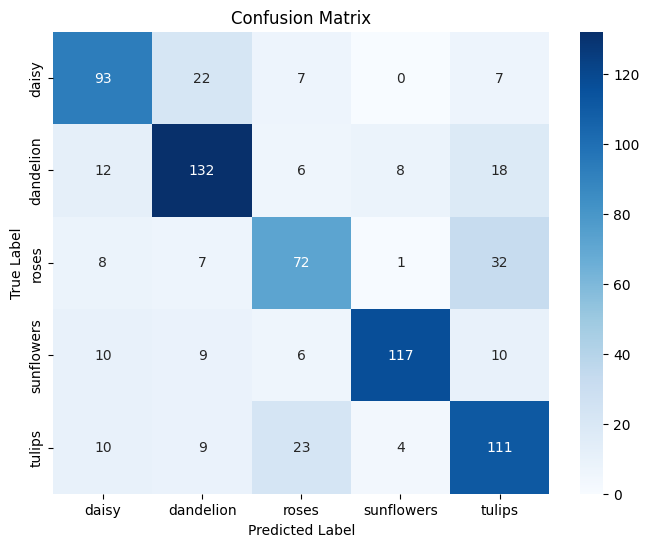

              precision    recall  f1-score   support

       daisy       0.70      0.72      0.71       129
   dandelion       0.74      0.75      0.74       176
       roses       0.63      0.60      0.62       120
  sunflowers       0.90      0.77      0.83       152
      tulips       0.62      0.71      0.66       157

    accuracy                           0.72       734
   macro avg       0.72      0.71      0.71       734
weighted avg       0.72      0.72      0.72       734



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect all true labels and predictions from the validation set
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

# Build the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot it nicely
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Print detailed metrics (precision, recall, f1-score per class)
print(classification_report(y_true, y_pred, target_names=class_names))

In [ ]:
from google.colab import files
import numpy as np

uploaded = files.upload()

Saving sunflower.png to sunflower (1).png


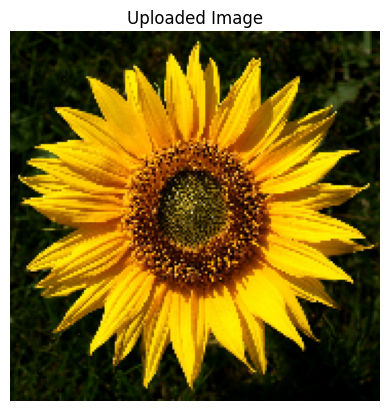

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
Prediction: sunflowers
Confidence: 99.64%


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Define standard image size (these were defined in a previous cell)
img_height = 180
img_width = 180

# Load and display the uploaded image
img_path = 'sunflower.png'  # changed to sunflower.png as it was uploaded

img = tf.keras.utils.load_img(img_path, target_size=(img_height, img_width))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)  # Create a batch of 1 image

# Show the image
plt.imshow(img)
plt.axis('off')
plt.title('Uploaded Image')
plt.show()

# Make prediction
predictions = model.predict(img_array)
score = tf.nn.softmax(predictions[0])

predicted_class = class_names[np.argmax(score)]
confidence = 100 * np.max(score)

print(f"Prediction: {predicted_class}")
print(f"Confidence: {confidence:.2f}%")

In [ ]:
import os
print(os.listdir())

['.config', 'daisy.webp', 'sunflower (1).png', 'sunflower.png', 'sample_data']


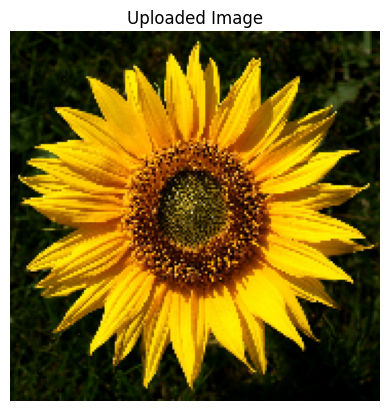

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Prediction: sunflowers
Confidence: 99.64%


In [ ]:
# Load and display the SECOND uploaded image (sunflower)
img_path = 'sunflower.png'  # <-- change this to match your exact uploaded filename

img = tf.keras.utils.load_img(img_path, target_size=(img_height, img_width))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

plt.imshow(img)
plt.axis('off')
plt.title('Uploaded Image')
plt.show()

predictions = model.predict(img_array)
score = tf.nn.softmax(predictions[0])

predicted_class = class_names[np.argmax(score)]
confidence = 100 * np.max(score)

print(f"Prediction: {predicted_class}")
print(f"Confidence: {confidence:.2f}%")

In [ ]:
loss, accuracy = model.evaluate(val_ds)
print(f"Final Validation Accuracy: {accuracy*100:.2f}%")
print(f"Final Validation Loss: {loss:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7153 - loss: 0.7261
Final Validation Accuracy: 71.53%
Final Validation Loss: 0.7261
